# Experiment 15: Dropout for widths 64 and 128

Card: [exp15_small_width_dropout.md](../../experiments/exp15_small_width_dropout.md)


In [15]:
import os
import sys

import matplotlib.pyplot as plt

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
sys.path.insert(0, "../..")  # the section's src package
from ashrae.config import FOLDS
from ashrae.plots import INK, SURFACE, TEXT
from ashrae.tracking import session_runs
from src.data import fold_loaders
from src.networks import MeterMLP
from src.plots import draw_curves
from src.runs import finished_keys, fold_table, session_scores
from src.tracking import Experiment
from src.training import fit_folds

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp15_small_width_dropout"
EMB_DIM = 12  # picked in exp03
LR = 1e-2
if SMOKE:
    EXPERIMENT = "ashrae-mlp-small-width-dropout-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTHS = [64]
    DROPOUTS = [0.3]
    # (experiment, session, widths, dropout) of the reused runs; None: the latest session
    REFERENCES = [
        ("ashrae-mlp-batch-norm-smoke", None, [64], 0.0),
        ("ashrae-mlp-width-smoke", None, [128], 0.0),
        (
            "ashrae-mlp-width-dropout-smoke",
            None,
            [128],
            0.3,
        ),  # stands in for 256 and 512
    ]
    FIGURES = None
else:
    EXPERIMENT = "ashrae-mlp-small-width-dropout"
    TRAIN = (
        False  # set False with SESSION to re-read a finished session without training
    )
    SESSION = "2026-10-13 09:06:41"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTHS = [64, 128]
    DROPOUTS = [0.1, 0.3]
    REFERENCES = [
        ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51", [64], 0.0),  # exp09
        ("ashrae-mlp-width", "2026-10-12 22:43:11", [128], 0.0),  # exp10
        ("ashrae-mlp-width-dropout", "2026-10-13 08:00:20", [256, 512], 0.3),  # exp14
    ]
    FIGURES = (
        "../../figures/exp15_small_width_dropout.png",
        "../../figures/exp15_small_width_dropout_best.png",
    )

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-small-width-dropout', session 2026-10-13 09:06:41


## Training


In [16]:
def scores():
    refs = []
    for name, session, widths, p in REFERENCES:
        ref = session_runs(name, session)
        ref = ref[ref["params.lr"].astype(float) == LR]
        if "width" in ref:  # exp09 trained width 64 only and has no width tag
            ref = ref[ref.width.astype(int).isin(widths)]
        else:
            ref = ref.assign(width=widths[0])
        if "dropout" in ref:  # exp09 and exp10 trained without dropout and have no dropout tag
            ref = ref[ref.dropout.astype(float) == p]
        refs.append(ref.assign(dropout=p))
    return session_scores(experiment, {"width": int, "dropout": float}, FOLD_NAMES, refs)

In [17]:
if TRAIN:
    folds, n_buildings, n_features = fold_loaders(FOLD_NAMES, N_TRAIN, N_VAL)
    done = (
        set()
        if SESSION is None
        else finished_keys(scores().query("width in @WIDTHS and dropout > 0"), ["width", "dropout", "fold"])
    )

    for width in WIDTHS:
        for p in DROPOUTS:
            fit_folds(
                experiment,
                folds,
                lambda: MeterMLP(
                    n_features,
                    n_buildings,
                    emb_dim=EMB_DIM,
                    batch_norm=True,
                    dropout=p,
                    width=width,
                ),
                f"mlp_4out_emb_bn | width {width} | dropout {p:g}",
                done=done,
                key=(width, p),
                epochs=EPOCHS,
                lr=LR,
                tags={"model": "mlp_4out_emb_bn", "width": str(width), "dropout": f"{p:g}"},
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM, "width": width, "dropout": p},
            )

## Results


In [18]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "val_last": f"average at epoch {EPOCHS}",
    "val_clean_last": f"average at epoch {EPOCHS}, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
table, by_setup = fold_table(results, ["width", "dropout"], columns, FOLD_NAMES)
display(table.round(3))

best = by_setup.val.groupby(level="width").idxmin().tolist()  # (width, dropout) pairs
print("best dropout per width:", ", ".join(f"{w}: {p:g}" for w, p in best))

MLflow session 2026-10-13 09:06:41: 32 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
width dropout                                                               
64    0.0                                         1.386    1.195    1.008   
      0.1                                         1.379    1.188    1.001   
      0.3                                         1.397    1.205    1.030   
128   0.0                                         1.392    1.198    1.004   
      0.1                                         1.375    1.193    1.003   
      0.3                                         1.389    1.194    1.013   
256   0.3                                         1.381    1.190    1.006   
512   0.3                                         1.378    1.185    1.001   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
width dropout                                                      
64    0.0                                         1.085    1.168   
      0.1                                         1.081    1.162   
      0.3                                         1.095    1.182   
128   0.0                                         1.085    1.170   
      0.1                                         1.080    1.163   
      0.3                                         1.084    1.170   
256   0.3                                         1.075    1.163   
512   0.3                                         1.072    1.159   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
width dropout                                                         
64    0.0                                                     0.912   
      0.1                                                     0.907   
      0.3                                                     0.941   
128   0.0                                                     0.908   
      0.1                                                     0.904   
      0.3                                                     0.926   
256   0.3                                                     0.907   
512   0.3                                                     0.901   

RMSLE at the best epoch, all rows unless noted  average at epoch 40  \
width dropout                                                         
64    0.0                                                     1.176   
      0.1                                                     1.165   
      0.3                                                     1.185   
128   0.0                                                     1.187   
      0.1                                                     1.170   
      0.3                                                     1.174   
256   0.3                                                     1.180   
512   0.3                                                     1.170   

RMSLE at the best epoch, all rows unless noted  average at epoch 40, clean rows  \
width dropout                                                                     
64    0.0                                                                 0.915   
      0.1                                                                 0.912   
      0.3                                                                 0.948   
128   0.0                                                                 0.915   
      0.1                                                                 0.905   
      0.3                                                                 0.924   
256   0.3                                                                 0.915   
512   0.3                                                                 0.913   

RMSLE at the best epoch, all rows unless noted  best epoch  \
width dropout                                                
64    0.0                                            35.25   
      0.1                                            27.75   
      0.3                                      

best dropout per width: 64: 0.1, 128: 0.1, 256: 0.3, 512: 0.3


In [19]:
SHADES = [
    "#9ec5f0",
    "#5b9be3",
    "#2a78d6",
    "#174e94",
]  # light to dark: dropout 0 to the largest in figure 1, width 64 to 512 in figure 2

CURVES = [
    ("val_curve", "validation RMSLE, all rows"),
    ("train_curve", "training RMSLE"),
]
baseline = results.query("width == 64 and dropout == 0")
best_runs = {(w, p): results.query("width == @w and dropout == @p") for w, p in best}


def finish(fig, path):
    fig.suptitle(
        f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam lr {LR:g}, batch 4096: mean over folds",
        x=0.01,
        ha="left",
        color=INK,
        fontsize=10,
    )
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
        for run_id in results.query("width in @WIDTHS and dropout > 0").run_id:
            experiment.client.log_artifact(run_id, path)


BASELINE = ("width 64, dropout 0 (baseline)", baseline, INK, "--", 1.0, 3)

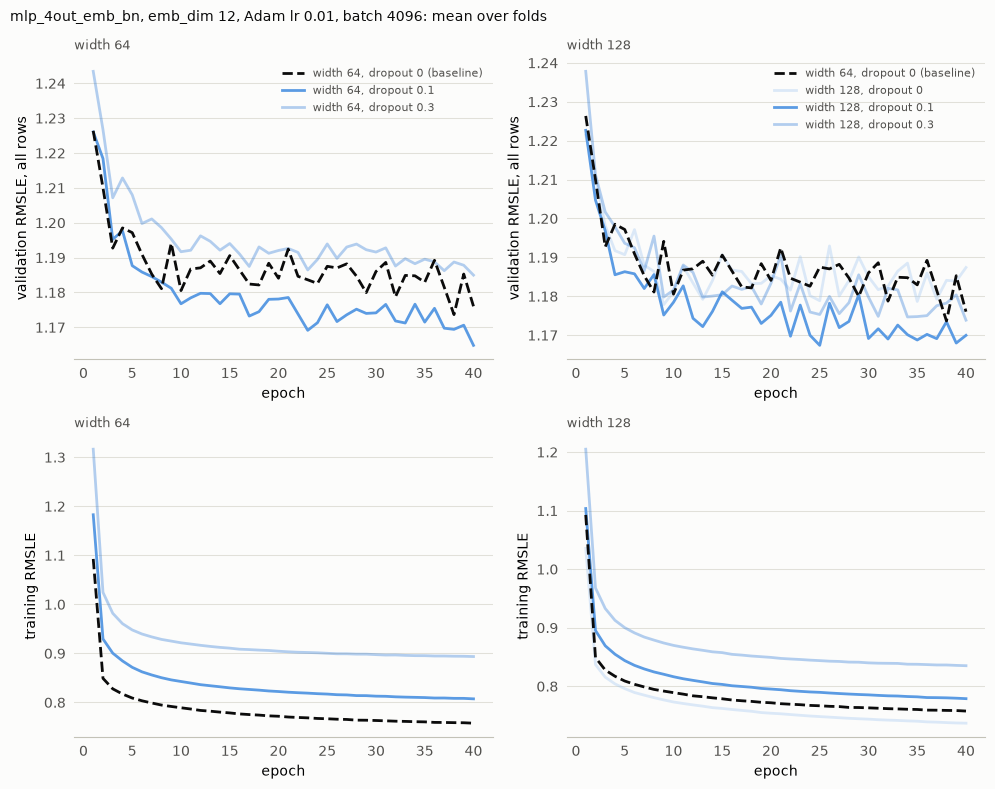

In [20]:
# Figure 1: each small width per dropout; the best dropout of each width in full color
fig, axes = plt.subplots(
    2, len(WIDTHS), figsize=(5 * len(WIDTHS), 8), facecolor=SURFACE, squeeze=False
)
for col, width in enumerate(WIDTHS):
    groups = [BASELINE] + [
        (
            f"width {width}, dropout {p:g}",
            runs,
            SHADES[i],
            "-",
            1.0 if (width, p) in best else 0.35,
            2,
        )
        for i, (p, runs) in enumerate(
            results.query("width == @width").groupby("dropout")
        )
        if (width, p) != (64, 0.0)  # drawn as the baseline
    ]
    for row, (key, label) in enumerate(CURVES):
        draw_curves(axes[row, col], groups, key, label, f"width {width}")
    axes[0, col].legend(frameon=False, fontsize=8, labelcolor=TEXT)
finish(fig, FIGURES and FIGURES[0])

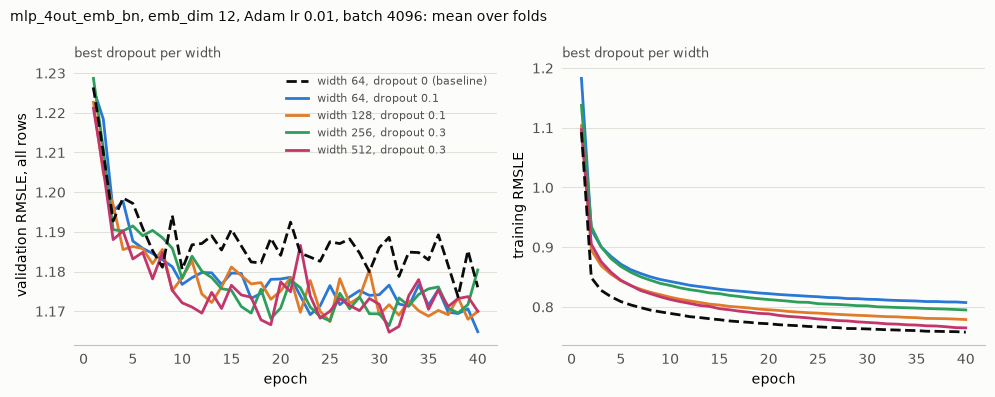

In [21]:
# Figure 2: every width at its best dropout, one distinct color per width
fig, axes = plt.subplots(1, 2, figsize=(10, 4), facecolor=SURFACE)
COLORS = ["#2a78d6", "#e07b29", "#2e9e5b", "#c2366b"]  # blue, orange, green, magenta
groups = [BASELINE] + [
    (f"width {w}, dropout {p:g}", runs, COLORS[i], "-", 1.0, 2)
    for i, ((w, p), runs) in enumerate(best_runs.items())
]
for ax, (key, label) in zip(axes, CURVES):
    draw_curves(ax, groups, key, label, "best dropout per width")
axes[0].legend(frameon=False, fontsize=8, labelcolor=TEXT)
finish(fig, FIGURES and FIGURES[1])